# HW 1: SIR and SEIR Model Implementation for Pandemic Spread
## Part A

In [1]:
import sys, pathlib, inspect
import numpy as np
import matplotlib.pyplot as plt

def find_root(start="."):
    p = pathlib.Path(start).resolve()
    for cand in [p, *p.parents]:
        if (cand / "epidemic_models.py").exists():
            return cand
    raise FileNotFoundError("repo root containing epidemic_models.py not found")

ROOT = find_root()
sys.path.insert(0, str(ROOT))
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 200, "font.size": 11,
                     "axes.grid": True, "grid.alpha": 0.3, "figure.autolayout": True})
print("repo root:", ROOT)

repo root: D:\Heng Sun(Jimmy)\Emory\Fall 2026\BMI500\week7\BMI500-HW7


In [2]:
for fn in ("sir_rhs", "forward_euler", "rk4"):
    import epidemic_models
    print(inspect.getsource(getattr(epidemic_models, fn)))

def sir_rhs(t, y, beta, gamma, N):
    """SIR model with *counts* (not fractions).

        dS/dt = -beta * S * I
        dI/dt =  beta * S * I - gamma * I
        dR/dt =  gamma * I

    Parameters
    ----------
    t : float          current time (days); the RHS is autonomous, kept for API
    y : array_like     state [S, I, R] (numbers of people)
    beta : float       transmission rate (per person per day)
    gamma : float      recovery rate (per day)
    N : float          total population (S + I + R). Unused in the RHS but kept
                       so that both models share the same calling signature.

    Returns
    -------
    numpy.ndarray of shape (3,)
    """
    S, I, R = y
    dS = -beta * S * I
    dI = beta * S * I - gamma * I
    dR = gamma * I
    return np.array([dS, dI, dR], dtype=float)

def forward_euler(rhs, y0, t0, t1, dt, **params):
    """Explicit (forward) Euler integration.

    y_{k+1} = y_k + dt * f(t_k, y_k)

    First-order accurate; used here mostly

## Part B

In [17]:
from epidemic_models import simulate_sir

N, S0, I0, R0_ = 2000.0, 1995.0, 5.0, 0.0
beta, gamma, t_end = 0.125e-3, 0.1, 160.0

t, S, I, R = simulate_sir(N, S0, I0, R0_, beta, gamma, t_end, dt=0.005)

ipk = int(np.argmax(I))
print(f"peak of I(t): day {t[ipk]:.2f}, I = {I[ipk]:.1f} people")
print(f"end of simulation: S={S[-1]:.1f}, I={I[-1]:.2f}, R={R[-1]:.1f}")

peak of I(t): day 42.55, I = 469.0 people
end of simulation: S=214.1, I=0.21, R=1785.7


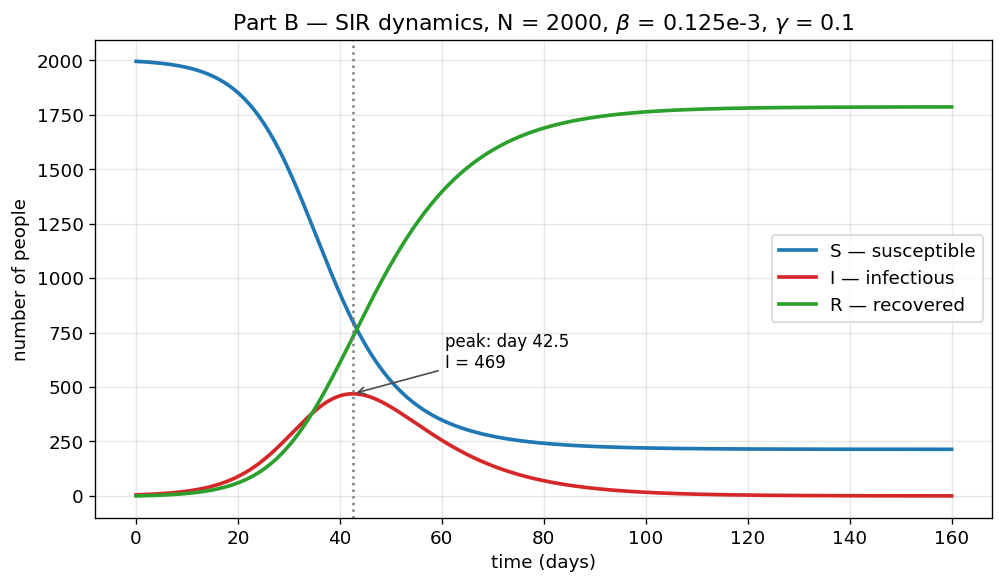

In [18]:
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(t, S, lw=2.2, color="#1f77b4", label="S — susceptible")
ax.plot(t, I, lw=2.2, color="#d62728", label="I — infectious")
ax.plot(t, R, lw=2.2, color="#2ca02c", label="R — recovered")
ax.axvline(t[ipk], color="0.5", ls=":", lw=1.5)
ax.annotate(f"peak: day {t[ipk]:.1f}\nI = {I[ipk]:.0f}",
            xy=(t[ipk], I[ipk]), xytext=(t[ipk] + 18, I[ipk] + 120),
            arrowprops=dict(arrowstyle="->", color="0.3"), fontsize=10)
ax.set_xlabel("time (days)"); ax.set_ylabel("number of people")
ax.set_title("Part B — SIR dynamics, N = 2000, $\\beta$ = 0.125e-3, $\\gamma$ = 0.1")
ax.legend(loc="center right")
fig.savefig(FIG / "partB_sir_timecourse.png", bbox_inches="tight")
plt.show()

## Part C

**(i) Infection peak.** $I(t)$ reaches its maximum of about **469 people on day 42.5**. The peak is
set by two competing effects: the supply of new infections, proportional to $\beta S I$, and the
recovered people, proportional to $\gamma I$. They balance exactly when $S=\gamma/\beta$.
Because $\gamma/\beta = 800$ is far below $S(0)=1995$, the epidemic has a long runway and a large peak.
A larger $\beta$ raises the peak (and brings it earlier), while a larger $\gamma$ both lowers the peak
and shortens the outbreak. The height of the peak also depends on how long the system lingers near
$S=\gamma/\beta$, which is why $S(0)$ and $N$ matter too.

**(ii) Basic reproduction number.** $R_0=\beta N/\gamma = (0.125\times10^{-3})(2000)/0.1 = 2.5$.
This means that, in a fully susceptible population, each infectious person generates on average 2.5
secondary infections. Every primary case therefore replaces itself more than once, so the outbreak
grows. $R_0>1$ is the condition for an epidemic to take off, and control measures must push $R_0$ below 1
(by reducing $\beta$, e.g. distancing/masks, or raising $\gamma$, e.g. faster detection and treatment),
and the *higher* $R_0$ is, the larger the fraction of the population that must be immunized,
roughly $1-1/R_0 = 60\%$ here, to reach herd immunity.

**(iii) Epidemic dynamics.** In the early phase $I$ grows nearly exponentially because $S\approx N$
so $dI/dt\approx(\beta N-\gamma)I$, i.e. growth rate $\gamma(R_0-1)$. As $S$ falls, the growth rate
decreases, and the epidemic peaks at $S=\gamma/\beta$. Afterwards $S$ keeps falling (more slowly) and
$R$ keeps rising until $I\to 0$ and the outbreak dies out, leaving a positive susceptible pool:
**about 214 people (10.7%) are never infected**, so the attack rate is about 89.3% ($R(160)=1786$).
The reason the outbreak stops before everyone is infected is that recovered people no longer transmit and the effective
reproduction number $R_{\text{eff}}=R_0 S/N$ falls below 1 once $S<N/R_0 = 800$.

## Part D

In [21]:
from scipy.signal import find_peaks
from epidemic_models import simulate_seir

P = dict(N=2000.0, S0=1980.0, E0=15.0, I0=5.0, R0_=0.0,
         beta=0.125e-3, gamma=0.1, sigma=0.25, mu=0.005)

t365, S3, E3, I3, R3 = simulate_seir(**P, t_end=365,  dt=0.005)
t15,  S15, E15, I15, R15 = simulate_seir(**P, t_end=1500, dt=0.005)

print("Part D.ii — 365 days")
i = int(np.argmax(I3))
print(f"  peak I = {I3[i]:.1f} on day {t365[i]:.1f}")
print(f"  at day 365: S={S3[-1]:.1f}, E={E3[-1]:.1f}, I={I3[-1]:.1f}, R={R3[-1]:.1f}")

print("\nPart D.ii — 1500 days")
pk, props = find_peaks(I15, prominence=2.0, distance=2000)
tr, _ = find_peaks(-I15, prominence=2.0, distance=2000)
print("  infection waves (day, peak I):")
for j, k in enumerate(pk, 1):
    print(f"    wave {j}: day {t15[k]:7.1f},  I = {I15[k]:6.1f}")
print("  inter-wave troughs (day, I):")
for k in tr:
    print(f"    trough : day {t15[k]:7.1f},  I = {I15[k]:6.1f}")
print("  wave periods (days):", np.round(np.diff(t15[pk]), 1))

Part D.ii — 365 days
  peak I = 316.9 on day 61.6
  at day 365: S=829.9, E=34.9, I=84.4, R=1050.8

Part D.ii — 1500 days
  infection waves (day, peak I):
    wave 1: day    61.6,  I =  316.9
    wave 2: day   359.2,  I =   84.8
    wave 3: day   648.1,  I =   59.6
  inter-wave troughs (day, I):
    trough : day   197.5,  I =   15.1
    trough : day   500.1,  I =   41.8
    trough : day   792.2,  I =   50.6
  wave periods (days): [297.7 288.8]


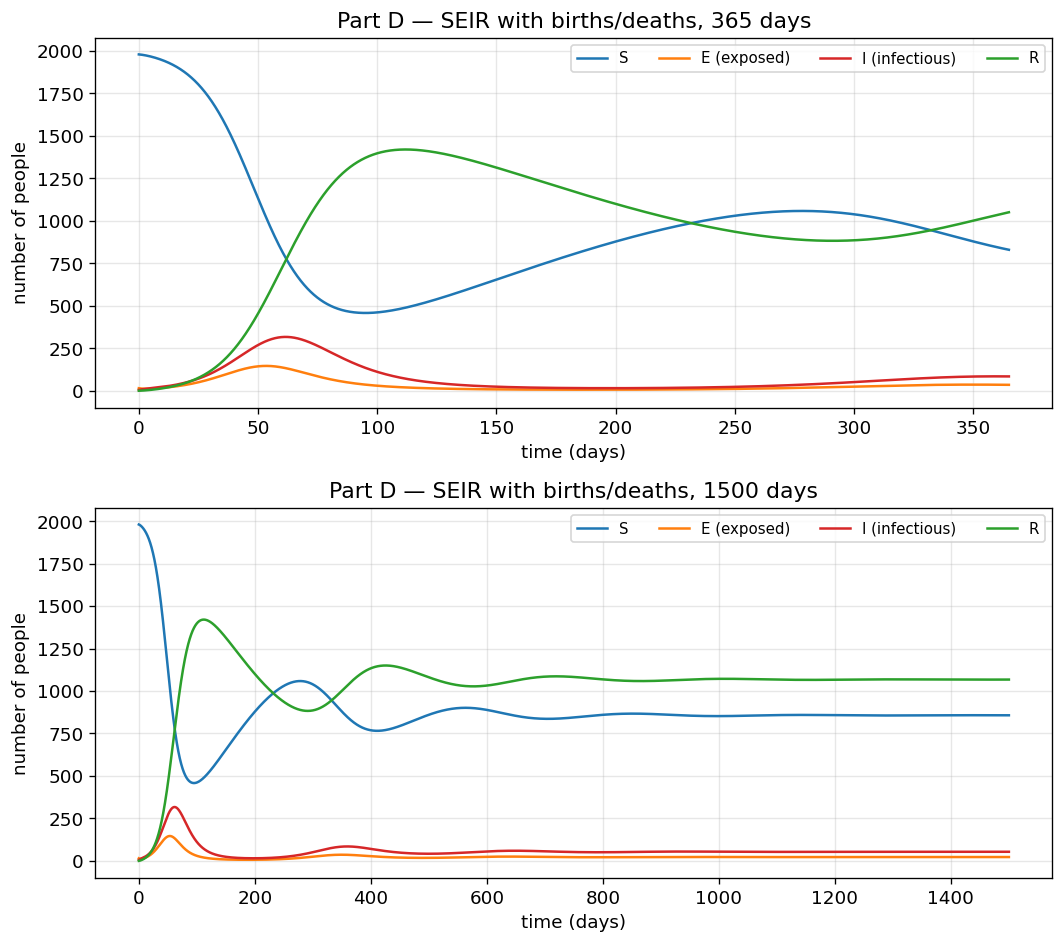

In [22]:
fig, ax = plt.subplots(2, 1, figsize=(9, 8), sharex=False)
for a, (tt, SS, EE, II, RR, title) in zip(
        ax, [(t365, S3, E3, I3, R3, "365 days"),
             (t15, S15, E15, I15, R15, "1500 days")]):
    a.plot(tt, SS, label="S", color="#1f77b4")
    a.plot(tt, EE, label="E (exposed)", color="#ff7f0e")
    a.plot(tt, II, label="I (infectious)", color="#d62728")
    a.plot(tt, RR, label="R", color="#2ca02c")
    a.set_xlabel("time (days)"); a.set_ylabel("number of people")
    a.set_title(f"Part D — SEIR with births/deaths, {title}")
    a.legend(ncol=4, loc="upper right", fontsize=9)
fig.savefig(FIG / "partD_seir_365_and_1500.png", bbox_inches="tight")
plt.show()

In [23]:
R0_seir = P["beta"] * P["N"] * P["sigma"] / ((P["sigma"] + P["mu"]) * (P["gamma"] + P["mu"]))
R0_sir  = P["beta"] * P["N"] / P["gamma"]
print(f"SEIR R0 = beta*N*sigma / ((sigma+mu)(gamma+mu)) = {R0_seir:.4f}")
print(f"SIR  R0 = beta*N/gamma                          = {R0_sir:.4f}")
print(f"=> adding the latent period LOWERS R0 by a factor sigma/(sigma+mu) ... "
      f"actually by (gamma+mu)/gamma = {(P['gamma']+P['mu'])/P['gamma']:.4f} and the latent factor.")

mask = t15 >= 1300
print(f"\nmean S over the last 200 days = {S15[mask].mean():.2f}")
print(f"N / R0                        = {P['N']/R0_seir:.2f}")
print(f"mean I over the last 200 days = {I15[mask].mean():.2f}  (endemic equilibrium)")
print(f"mean R over the last 200 days = {R15[mask].mean():.2f}")

SEIR R0 = beta*N*sigma / ((sigma+mu)(gamma+mu)) = 2.3343
SIR  R0 = beta*N/gamma                          = 2.5000
=> adding the latent period LOWERS R0 by a factor sigma/(sigma+mu) ... actually by (gamma+mu)/gamma = 1.0500 and the latent factor.

mean S over the last 200 days = 856.83
N / R0                        = 856.80
mean I over the last 200 days = 53.31  (endemic equilibrium)
mean R over the last 200 days = 1067.47


In [24]:
from epidemic_models import simulate_sir

# SEIR with mu = 0 (no births/deaths) -> compare single vs repeated waves
tx, Sx, Ex, Ix, Rx = simulate_seir(N=2000., S0=1980., E0=15., I0=5., R0_=0.,
                                   beta=0.125e-3, gamma=0.1, sigma=0.25, mu=0.0,
                                   t_end=1500, dt=0.01)
# plain SIR with the same beta, gamma (no E compartment)
ts, Ss, Is, Rs = simulate_sir(2000., 5., 0., 0.0, 0.125e-3, 0.1, 400, dt=0.01)

print("Comparing the first wave")
print(f"  SIR  (no E):      peak I = {Is.max():6.1f} on day {ts[int(np.argmax(Is))]:5.1f}")
print(f"  SEIR (mu=0):      peak I = {Ix.max():6.1f} on day {tx[int(np.argmax(Ix))]:5.1f}")
print(f"  SEIR (mu=0.005):  peak I = {I3.max():6.1f} on day {t365[int(np.argmax(I3))]:5.1f}")
print(f"  SIR  final S = {Ss[-1]:.1f}   SEIR(mu=0) final S = {Sx[-1]:.1f}")

print(f"\nNumber of infection events (integral of beta*S*I):")
print(f"  first 365 days : {np.trapezoid(P['beta']*S3*I3, t365):.0f} people")
print(f"  full 1500 days : {np.trapezoid(P['beta']*S15*I15, t15):.0f} people")

Comparing the first wave
  SIR  (no E):      peak I =    0.0 on day   0.0
  SEIR (mu=0):      peak I =  335.4 on day  58.2
  SEIR (mu=0.005):  peak I =  316.9 on day  61.6
  SIR  final S = 5.0   SEIR(mu=0) final S = 211.8

Number of infection events (integral of beta*S*I):
  first 365 days : 3075 people
  full 1500 days : 9561 people


**(iii) Waves.** With births and deaths the outbreak is **not** a single event. The first wave peaks
at **day 61.6 with about 317 infectious people**. $I$ then falls to a trough of ~15 people around
day 197, and when the birth term has refilled the susceptible pool the infection breaks out again.
The next peaks of about **85 people (day 359)**, **60 people (day 648)** and **55 people (day 938)**,
separated by roughly **290 days**. So there is one large first wave followed by smaller, damped
recurrent waves. The 365-day window shows only the first wave and the start of the second, whereas
1500 days reveals the recurrent pattern.

**(iv) $R_0$ comparison.** For the SEIR model
$R_0=\frac{\beta N\sigma}{(\sigma+\mu)(\gamma+\mu)}=\frac{(0.125\times10^{-3})(2000)(0.25)}{(0.255)(0.105)}=2.33$,
slightly **below** the SIR value of 2.50. Reasons behind it is that the latent period means an exposed
person is not yet infectious (a factor $\sigma/(\sigma+\mu)$), and the death term removes people from
each compartment (the $(\gamma+\mu)$ and $(\sigma+\mu)$ factors). Numerically, the mean susceptible
level over the last 200 days of the 1500-day run is **857**, in excellent agreement with
$N/R_0=2000/2.33=857$. This number is the **endemic susceptible level**: with births continuously
adding new susceptibles, the population settles into a state where $S=N/R_0$ exactly, so that the
effective reproduction number $R_{\text{eff}}=R_0 S/N=1$ and each infection is replaced by precisely
one new infection — the infection persists indefinitely instead of dying out.

**(v) Effect of the exposed compartment and of births/deaths.** With the same transmission parameters the SEIR peak (317, day 61.6) is smaller and later than
the SIR peak (469, day 42.4). Slowing transmission through a latent stage therefore flattens the
curve, which is exactly the public-health argument for "flattening the peak." Births and deaths are
what make the waves recur. With $\mu=0$ the SEIR model gives a single wave that dies out (final
$S\approx212$ and $I\to0$), whereas $\mu=0.005$ keeps replenishing susceptibles and produces damped
oscillations forever. The chosen $\mu=0.005\,\text{day}^{-1}$ is unrealistically large, it corresponds
to an average lifespan of only 200 days and is deliberately inflated so that the slow demographic
oscillation is visible within a short simulation. With a realistic human lifespan ($\mu\sim1/70\,\text{yr}\approx4\times10^{-5}\,\text{day}^{-1}$)
the same phenomenon would appear but the inter-wave period would be of the order of the generation
time of the infection multiplied by the demographic turnover, such as many years to decades rather than
~290 days. Therefore over a realistic horizon the epidemic would look like a single outbreak rather than a
rapidly repeating series of waves.

## Part E

In [25]:
from epidemic_models import simulate_seir

betas  = np.linspace(0.05e-3, 0.25e-3, 11)
gammas = np.linspace(0.05, 0.25, 11)
sigma, mu = 0.25, 0.005

peakI  = np.zeros((len(gammas), len(betas)))
totinf = np.zeros_like(peakI)
R0grid = np.zeros_like(peakI)
for j, b in enumerate(betas):
    for i, g in enumerate(gammas):
        tt, SS, EE, II, RR = simulate_seir(2000., 1980., 15., 5., 0., b, g, sigma, mu, 365, dt=0.02)
        peakI[i, j]  = II.max()
        totinf[i, j] = np.trapezoid(b * SS * II, tt)
        R0grid[i, j] = b * 2000. * sigma / ((sigma + mu) * (g + mu))

print("peak I   range:", peakI.min().round(1), "->", peakI.max().round(1))
print("total new infections over 365 d:", int(totinf.min()), "->", int(totinf.max()))
print("R0 range:", R0grid.min().round(2), "->", R0grid.max().round(2))

peak I   range: 8.0 -> 1036.3
total new infections over 365 d: 12 -> 4866
R0 range: 0.38 -> 8.91


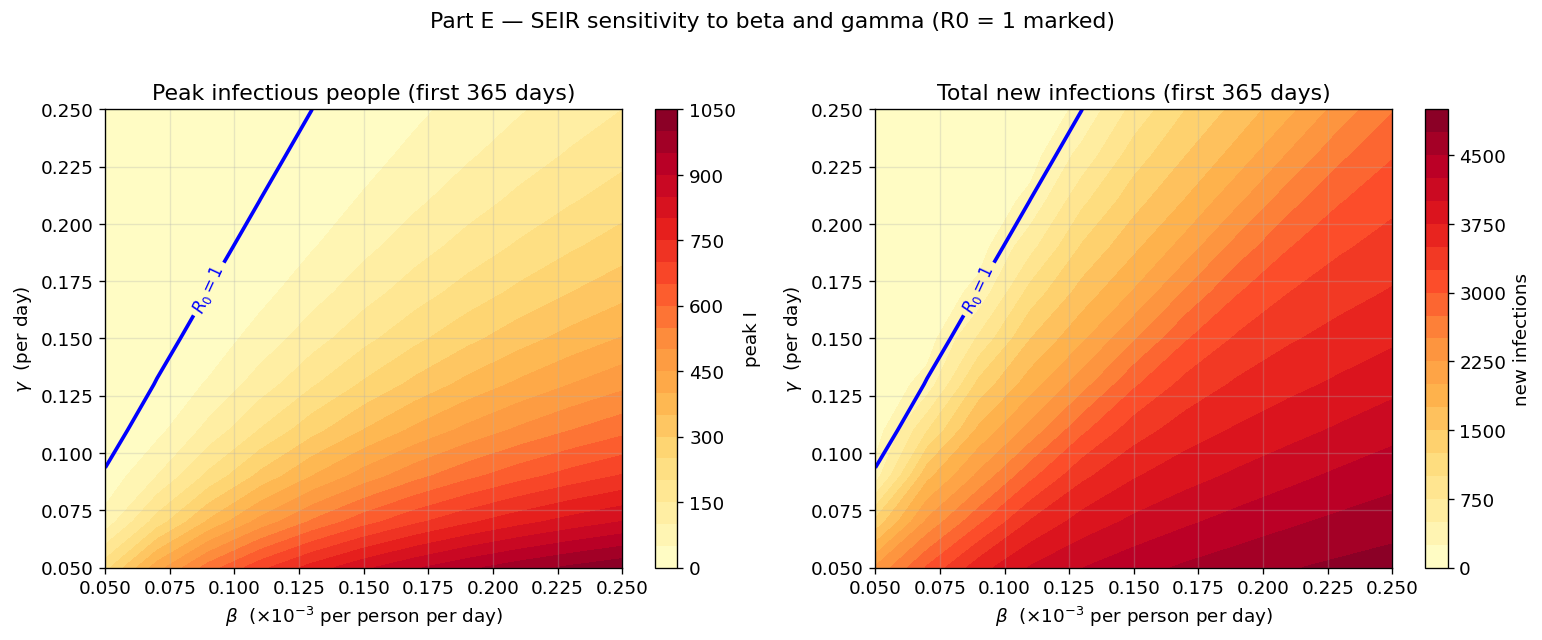

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
X, Y = np.meshgrid(betas * 1e3, gammas)

for a, Z, ttl, cbl in [
        (ax[0], peakI,  "Peak infectious people (first 365 days)", "peak I"),
        (ax[1], totinf, "Total new infections (first 365 days)",   "new infections")]:
    cs = a.contourf(X, Y, Z, levels=20, cmap="YlOrRd")
    fig.colorbar(cs, ax=a, label=cbl)
    cc = a.contour(X, Y, R0grid, levels=[1], colors="blue", linewidths=2.2)  # R0 = 1
    a.clabel(cc, fmt={1: r"$R_0=1$"}, fontsize=10)
    a.set_xlabel(r"$\beta$  ($\times 10^{-3}$ per person per day)")
    a.set_ylabel(r"$\gamma$  (per day)")
    a.set_title(ttl)

fig.suptitle("Part E — SEIR sensitivity to beta and gamma (R0 = 1 marked)", y=1.02)
fig.savefig(FIG / "partE_sensitivity_heatmaps.png", bbox_inches="tight")
plt.show()

In [27]:
# Quantify which parameter moves the peak more, at the Part D anchor.
# We use the local (log-log) elasticity:  e_x = d ln(peak) / d ln(x).
anchor_b, anchor_g = 0.125e-3, 0.1
def peak_at(b, g, t_end=365):
    tt, SS, EE, II, RR = simulate_seir(2000., 1980., 15., 5., 0., b, g, sigma, mu, t_end, dt=0.01)
    return II.max()

h = 0.05  # +-5% perturbation
e_b = (np.log(peak_at(anchor_b*(1+h), anchor_g)) - np.log(peak_at(anchor_b/(1+h), anchor_g))) \
      / (np.log(1+h) - np.log(1/(1+h)))
e_g = (np.log(peak_at(anchor_b, anchor_g*(1+h))) - np.log(peak_at(anchor_b, anchor_g/(1+h)))) \
      / (np.log(1+h) - np.log(1/(1+h)))
print(f"elasticity of the peak w.r.t. beta  = {e_b:+.2f}")
print(f"elasticity of the peak w.r.t. gamma = {e_g:+.2f}")
print(f"=> |gamma| / |beta| = {abs(e_g/e_b):.2f}, so gamma moves the peak slightly MORE than beta")

# Control experiment: hold R0 FIXED and move gamma (beta follows) -- isolates the
# part of the effect that is *not* explained by R0.
R0_fixed = anchor_b*2000.*sigma / ((sigma + mu)*(anchor_g + mu))
print(f"\niso-R0 control with R0 held at {R0_fixed:.3f}:")
for g in [0.05, 0.10, 0.15, 0.20, 0.25]:
    b = R0_fixed*(sigma + mu)*(g + mu) / (2000.*sigma)
    print(f"  gamma = {g:5.3f}   beta = {b*1e3:6.3f}e-3   peak I = {peak_at(b, g):7.1f}")
print("  => even at fixed R0 a larger gamma lowers the peak, because gamma also sets")
print("     how fast infectious people are removed (the epidemic time scale).")

elasticity of the peak w.r.t. beta  = +1.58
elasticity of the peak w.r.t. gamma = -1.84
=> |gamma| / |beta| = 1.16, so gamma moves the peak slightly MORE than beta

iso-R0 control with R0 held at 2.334:
  gamma = 0.050   beta =  0.065e-3   peak I =   387.1
  gamma = 0.100   beta =  0.125e-3   peak I =   316.9
  gamma = 0.150   beta =  0.185e-3   peak I =   272.9
  gamma = 0.200   beta =  0.244e-3   peak I =   240.7
  gamma = 0.250   beta =  0.304e-3   peak I =   215.8
  => even at fixed R0 a larger gamma lowers the peak, because gamma also sets
     how fast infectious people are removed (the epidemic time scale).


**(iii) Discussion.** $\beta$ combines contact rate and per-contact transmission, so it is the
parameter that social distancing, masking and vaccination act on. $\gamma$ is set by the biology of
the pathogen, so it can only be changed indirectly, through treatment, antivirals and faster case
detection. In practice $\beta$-type measures are the ones that can be pushed far enough to bring
$R_0$ below 1, and this matters because the transition around $R_0=1$ is steep: moving below the
line removes the wave, whereas sliding along it does not.